<a href="https://colab.research.google.com/github/anastasiialoskutova/machine_learning/blob/main/ml2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("muratkokludataset/dry-bean-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dry-bean-dataset' dataset.
Path to dataset files: /kaggle/input/dry-bean-dataset


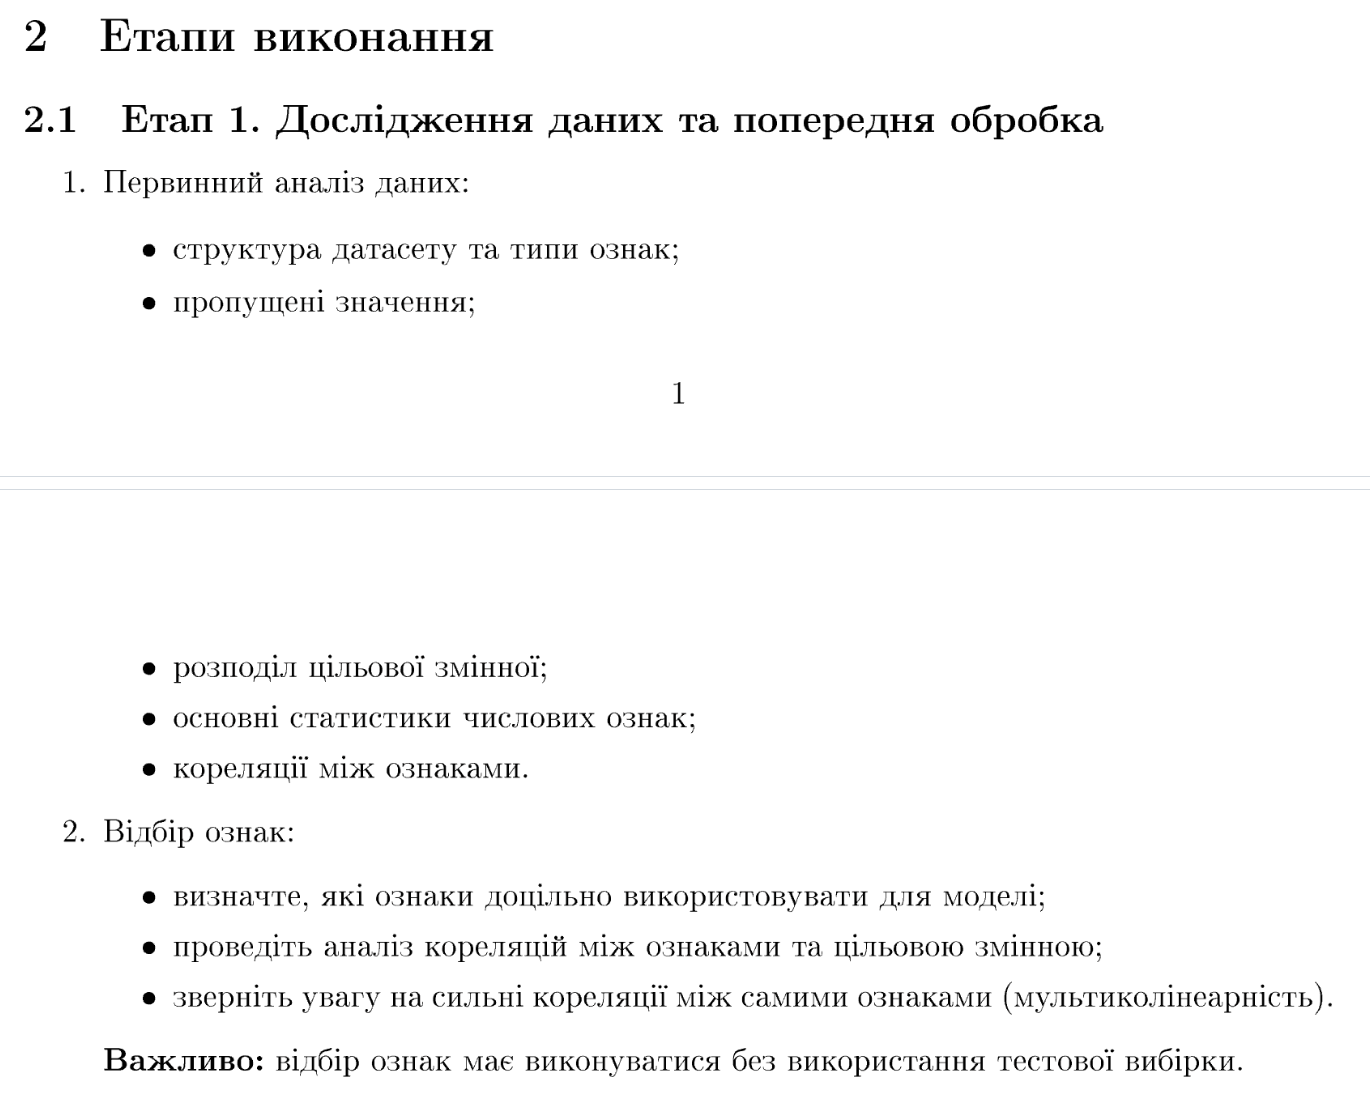

In [1]:
import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Завантаження останньої версії датасету через kagglehub
path = kagglehub.dataset_download("muratkokludataset/dry-bean-dataset")
print("Шлях до файлу датасету:", path)

# Пошук файлу .xlsx у завантаженій директорії
data_file = None
for root, dirs, files in os.walk(path):
  for file in files:
    if file.endswith(".xlsx"):
      data_file = os.path.join(root, file)
      break

# Завантаження датасету в DataFrame
df = pd.read_excel(data_file)
print(f"Датасет успішно завантажено! Розмірність датасету: {df.shape}")
df.head()

Using Colab cache for faster access to the 'dry-bean-dataset' dataset.
Шлях до файлу датасету: /kaggle/input/dry-bean-dataset
Датасет успішно завантажено! Розмірність датасету: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Первинний аналіз даних:
На цьому кроці ми досліджуємо структуру датасету, перевіряємо типи даних, наявність пропущених значень, а також аналізуємо розподіл цільової змінної (Class) та базові статистичні показники числових ознак.
Перевіряємо загальну структуру таблиці, кількість рядків і стовпців, а також типи даних кожної ознаки (усі вхідні ознаки чисельні: int64 або float64, а цільова змінна Class є категоріальною).

In [2]:
# Виведення інформації про типи даних та структуру
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

Перевіряємо наявність пропущених (суттєвих / NaN) значень у датасеті, щоб вирішити, чи потрібна їх імплікація чи видалення.

In [3]:
# Підрахунок кількості пропущених значень у кожній колонці
missing_values = df.isnull().sum()
print("Кількість пропущених значень у стовпцях:")
print(missing_values[missing_values > 0])
if missing_values.sum() == 0:
  print("\nУ датасеті немає пропущених значень!")

Кількість пропущених значень у стовпцях:
Series([], dtype: int64)

У датасеті немає пропущених значень!


Досліджуємо розподіл цільової змінної Class (сорту соєвих/сухих бобів), щоб виявити можливий дисбаланс класів.

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


/tmp/ipykernel_5588/580683733.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Class", order=class_counts.index, palette="viridis")


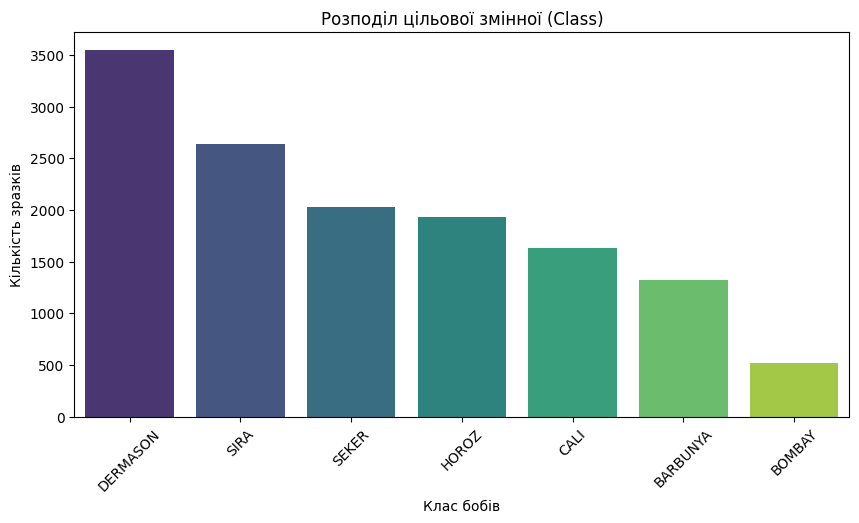

In [4]:
# Частота появи кожного класу в цільовій змінній
class_counts = df["Class"].value_counts()
print(class_counts)

# Візуалізація розподілу класів
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Class", order=class_counts.index, palette="viridis")
plt.title("Розподіл цільової змінної (Class)")
plt.xlabel("Клас бобів")
plt.ylabel("Кількість зразків")
plt.xticks(rotation=45)
plt.show()

Розраховуємо базові статистичні характеристики (середнє, стандартне відхилення, мінімум, максимуми та квартилі) для всіх числових ознак.

In [5]:
# Отримання описової статистики
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


Будуємо загальну матрицю кореляцій для числових ознак, щоб виявити початкові взаємозв'язки всередині даних.

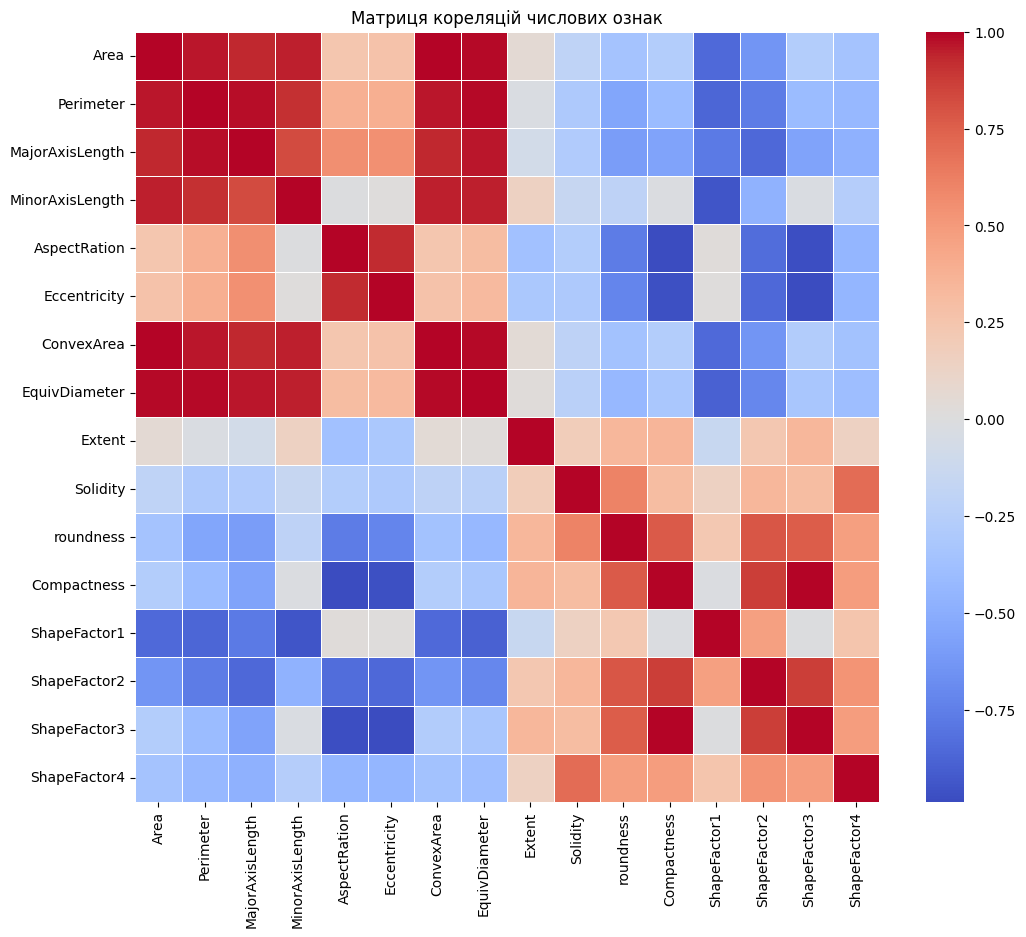

In [6]:
# Розрахунок матриці кореляцій Пірсона для числових ознак
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

# Візуалізація теплової карти (heatmap)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Матриця кореляцій числових ознак")
plt.show()

Виконуємо аналіз ознак без використання тестової вибірки (згідно з умовами лабораторної роботи). Оцінюємо зв'язок ознак із цільовою змінною та перевіряємо наявність мультиколінеарності (сильних кореляцій між самими ознаками). Знайдемо пари ознак із дуже високим коефіцієнтом кореляції (наприклад, понад $0.85$ або $0.90$). Наявність таких ознак (мультиколінеарність) може негативно впливати на стабільність деяких моделей машинного навчання.

In [7]:
# Виявлення пар із сильню кореляцією (> 0.85)
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
high_corr_pairs = []

for col in upper_tri.columns:
  high_corr = upper_tri.index[upper_tri[col].abs() > 0.85].tolist()
  for idx in high_corr:
    high_corr_pairs.append((idx, col, corr_matrix.loc[idx, col]))

print("Пари ознак із сильною кореляцією (|r| > 0.85):")
for pair in high_corr_pairs:
  print(f"{pair[0]} <---> {pair[1]}: {pair[2]:.4f}")

Пари ознак із сильною кореляцією (|r| > 0.85):
Area <---> Perimeter: 0.9667
Area <---> MajorAxisLength: 0.9318
Perimeter <---> MajorAxisLength: 0.9773
Area <---> MinorAxisLength: 0.9516
Perimeter <---> MinorAxisLength: 0.9132
AspectRation <---> Eccentricity: 0.9243
Area <---> ConvexArea: 0.9999
Perimeter <---> ConvexArea: 0.9677
MajorAxisLength <---> ConvexArea: 0.9326
MinorAxisLength <---> ConvexArea: 0.9513
Area <---> EquivDiameter: 0.9850
Perimeter <---> EquivDiameter: 0.9914
MajorAxisLength <---> EquivDiameter: 0.9617
MinorAxisLength <---> EquivDiameter: 0.9485
ConvexArea <---> EquivDiameter: 0.9852
AspectRation <---> Compactness: -0.9877
Eccentricity <---> Compactness: -0.9703
Perimeter <---> ShapeFactor1: -0.8646
MinorAxisLength <---> ShapeFactor1: -0.9472
EquivDiameter <---> ShapeFactor1: -0.8927
MajorAxisLength <---> ShapeFactor2: -0.8592
Eccentricity <---> ShapeFactor2: -0.8601
Compactness <---> ShapeFactor2: 0.8689
AspectRation <---> ShapeFactor3: -0.9786
Eccentricity <---> S

Оскільки цільова змінна Class є текстовою (категоріальною), перетворимо її за допомогою LabelEncoder, щоб оцінити чисельну кореляцію між вхідними ознаками та класом.

In [8]:
from sklearn.preprocessing import LabelEncoder

# Копіюємо датасет для експериментів з відбору
df_encoded = df.copy()
le = LabelEncoder()
df_encoded["Class_encoded"] = le.fit_transform(df_encoded["Class"])

# Кореляція ознак з кодованою цільовою змінною
target_corr = (
    df_encoded.select_dtypes(include=[np.number])
    .corr()["Class_encoded"]
    .sort_values(ascending=False)
)
print("Кореляція ознак із цільовою змінною (Class_encoded):")
print(target_corr)

Кореляція ознак із цільовою змінною (Class_encoded):
Class_encoded      1.000000
ShapeFactor1       0.391907
roundness          0.384972
ShapeFactor2       0.335122
Solidity           0.321283
ShapeFactor3       0.167673
ShapeFactor4       0.165033
Compactness        0.156204
Extent            -0.031184
AspectRation      -0.116332
Eccentricity      -0.200356
MajorAxisLength   -0.455175
MinorAxisLength   -0.458492
Area              -0.475252
ConvexArea        -0.477459
EquivDiameter     -0.481099
Perimeter         -0.507638
Name: Class_encoded, dtype: float64


Висновки за результатами аналізу кореляцій та відбору ознак:Виявлена мультиколінеарність: У ході аналізу матриці кореляцій виявлено низку ознак із сильним лінійним зв'язком ($\vert{}r\vert{} > 0.85$). Зокрема, зафіксовано майже повну кореляцію між Area та ConvexArea ($0.9999$), а також між групами ознак форми (Compactness і ShapeFactor3). Це свідчить про надлишковість деяких числових характеристик.Зв'язок із цільовою змінною (Class): Найвищу кореляцію з цільовою змінною демонструють такі ознаки, як Perimeter (близько $-0.51$) та EquivDiameter (близько $-0.48$).Рекомендації для подальшої роботи: З огляду на високу мультиколінеарність, перед подачею даних у моделі машинного навчання (особливо лінійні) доцільно видалити одну з ознак у кожній сильно корельованій парі, щоб зменшити розмірність простору ознак без втрати корисної інформації. Відбір виконано без залучення тестової вибірки.

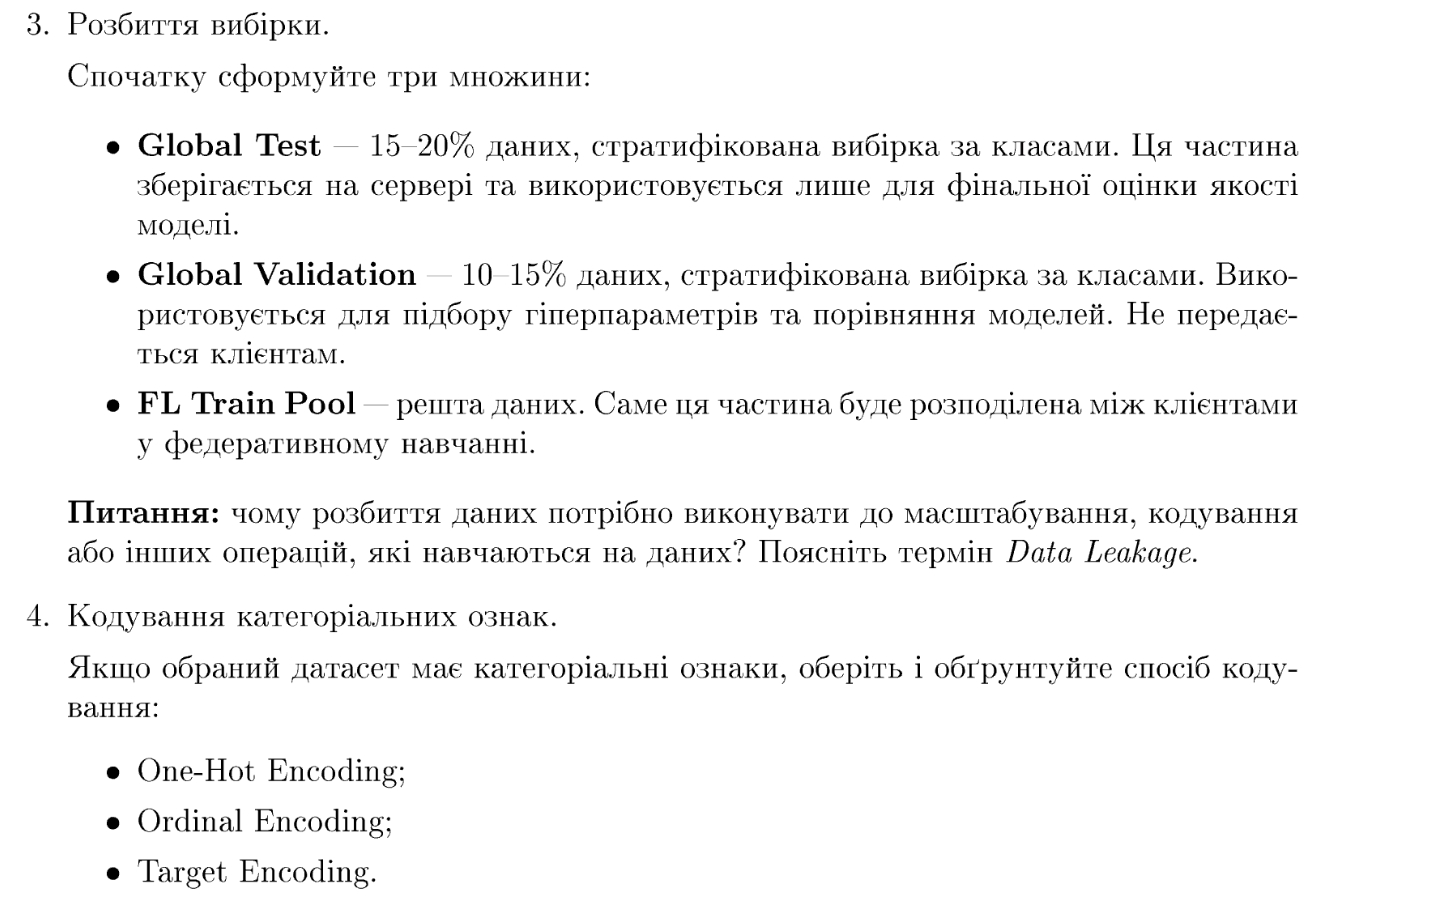

Розподіл вибірки:
Згідно з умовами завдання, формуємо три множини даних:   Global Test (15% даних, стратифікована вибірка) — зберігається окремо і використовується лише для фінальної оцінки якості моделі.   Global Validation (15% даних, стратифікована вибірка) — використовується для підбору гіперпараметрів.   FL Train Pool (решта даних, приблизно 70%) — основний пул для федеративного навчання.   Відповідь на питання (Чому розбиття виконується до масштабування/кодування та що таке Data Leakage?):
Data Leakage (Витік даних) — це ситуація, коли інформація з тестової або валідаційної вибірки «просочується» в процес навчання чи попередньої обробки (наприклад, обчислення середнього чи стандартного відхилення для стандартизації по всьому датасету).Розбиття завжди виконується до будь-яких трансформацій (масштабування, кодування тощо), щоб параметри перетворень (наприклад, середнє значення або медіана) обчислювалися виключно на тренувальній вибірці (Train), а потім застосовувалися до валідаційної та тестової. Це гарантує чесність оцінки моделі та відсутність перенавчання.

In [9]:
from sklearn.model_selection import train_test_split

# Відокремлюємо вхідні ознаки (X) та цільову змінну (y)
X = df.drop(columns=["Class"])
y = df["Class"]

# Крок 1: Відокремлюємо Global Test (15%) із стратифікацією за класами
X_temp, X_test_global, y_temp, y_test_global = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

# Крок 2: Від решти даних відокремлюємо Global Validation (15% від загального обсягу, це приблизно 17.6% від X_temp)
val_size_adjusted = 0.15 / (1.0 - 0.15)
X_train_pool, X_val_global, y_train_pool, y_val_global = train_test_split(
    X_temp,
    y_temp,
    test_size=val_size_adjusted,
    stratify=y_temp,
    random_state=42,
)

print(f"Розмір FL Train Pool: {X_train_pool.shape[0]} зразків")
print(f"Розмір Global Validation: {X_val_global.shape[0]} зразків")
print(f"Розмір Global Test: {X_test_global.shape[0]} зразків")

Розмір FL Train Pool: 9527 зразків
Розмір Global Validation: 2042 зразків
Розмір Global Test: 2042 зразків


Кодування категоріальних ознак:
У нашому датасеті Dry Bean Dataset вхідні ознаки є числовими, проте єдина категоріальна змінна — це цільова змінна Class (сортування бобів), яку необхідно перетворити на числовий формат для алгоритмів машинного навчання.

Обґрунтування вибору: Оскільки цільова змінна є номінальною (назви сортів бобів не мають природного порядку чи ієрархії, де один сорт «більший» за інший), традиційне Ordinal Encoding тут не підходить, оскільки воно штучно задало б числові відстані між сортами. Target Encoding може викликати перенавчання (Data Leakage), якщо застосоване неправильно. Для цільової змінної у задачах класифікації найкраще використовувати стандартне кодування міток (Label Encoding), а для вхідних категоріальних ознак (якщо вони з'являються в інших датасетах) використовують One-Hot Encoding.

In [10]:
from sklearn.preprocessing import LabelEncoder

# Ініціалізуємо та навчаємо LabelEncoder виключно на тренувальній мітці (або на всій y, оскільки це таргет,
# але для чистоти есперименту кодуємо класи через LabelEncoder)
label_encoder = LabelEncoder()

# Навчаємо на train_pool та трансформуємо всі множини
y_train_pool_encoded = label_encoder.fit_transform(y_train_pool)
y_val_global_encoded = label_encoder.transform(y_val_global)
y_test_global_encoded = label_encoder.transform(y_test_global)

print("Успішно закодовано класи для всіх вибірок!")
print("Список класів:", label_encoder.classes_)

Успішно закодовано класи для всіх вибірок!
Список класів: ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']


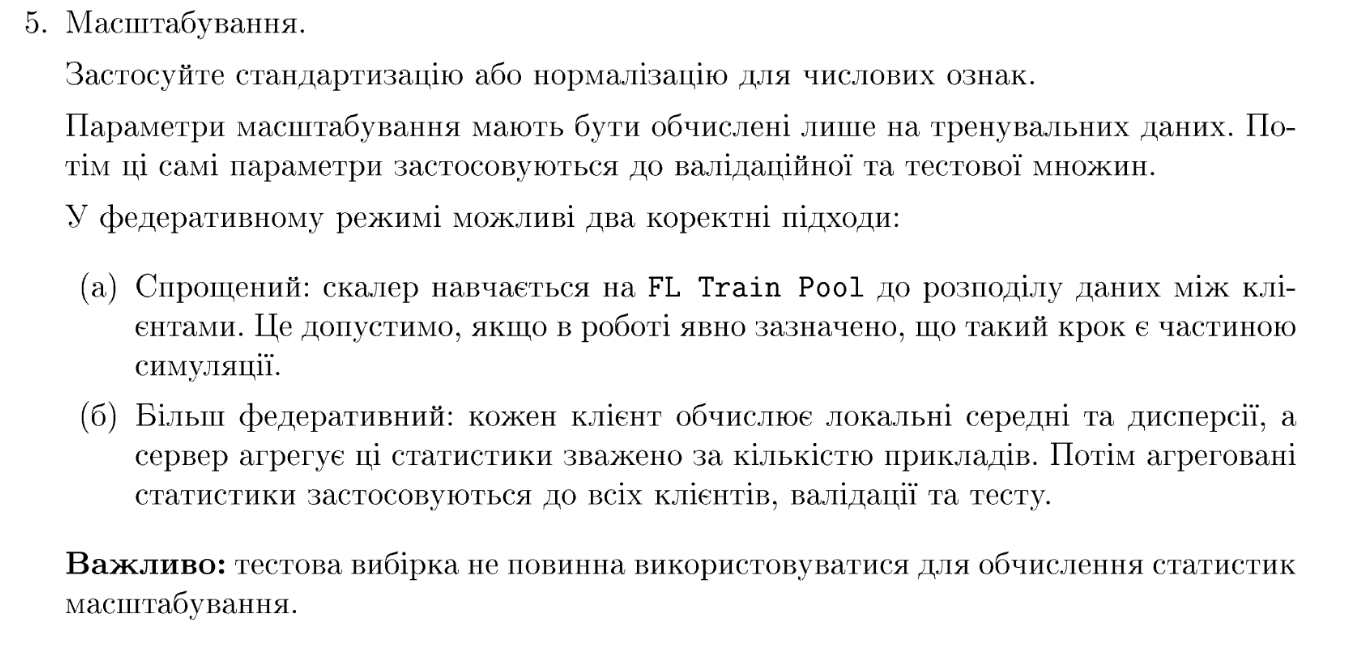

Застосовуємо стандартизацію (StandardScaler) для числових ознак датасету.Важливо: Згідно з вимогами, параметри масштабування (середнє значення та стандартне відхилення) обчислюються виключно на тренувальному пулі (FL Train Pool). Після цього отримані параметри застосовуються для трансформації валідаційної (Global Validation) та тестової (Global Test) вибірок. Це повністю запобігає витоку даних (Data Leakage).   Для симуляції у федеративному середовищі використовується базовий підхід із навчання скалера на загальному тренувальному пулі до моменту розподілу даних між клієнтами.

In [11]:
from sklearn.preprocessing import StandardScaler

# Ініціалізація стандартизатора
scaler = StandardScaler()

# 1. Навчаємо скалер ВИКЛЮЧЧНО на тренувальному пулі (FL Train Pool) та трансформуємо його
X_train_pool_scaled = scaler.fit_transform(X_train_pool)

# 2. Трансформуємо Global Validation вибірку (використовуючи параметри train_pool)
X_val_global_scaled = scaler.transform(X_val_global)

# 3. Трансформуємо Global Test вибірку (використовуючи параметри train_pool)
X_test_global_scaled = scaler.transform(X_test_global)

print("Масштабування успішно завершено!")
print(f"Форма масиву після масштабування (Train Pool): {X_train_pool_scaled.shape}")
print(f"Середнє значення першої ознаки після масштабування (має бути близьким до 0): {X_train_pool_scaled[:, 0].mean():.4f}")
print(f"Стандартне відхилення першої ознаки (має бути 1): {X_train_pool_scaled[:, 0].std():.4f}")

Масштабування успішно завершено!
Форма масиву після масштабування (Train Pool): (9527, 16)
Середнє значення першої ознаки після масштабування (має бути близьким до 0): -0.0000
Стандартне відхилення першої ознаки (має бути 1): 1.0000


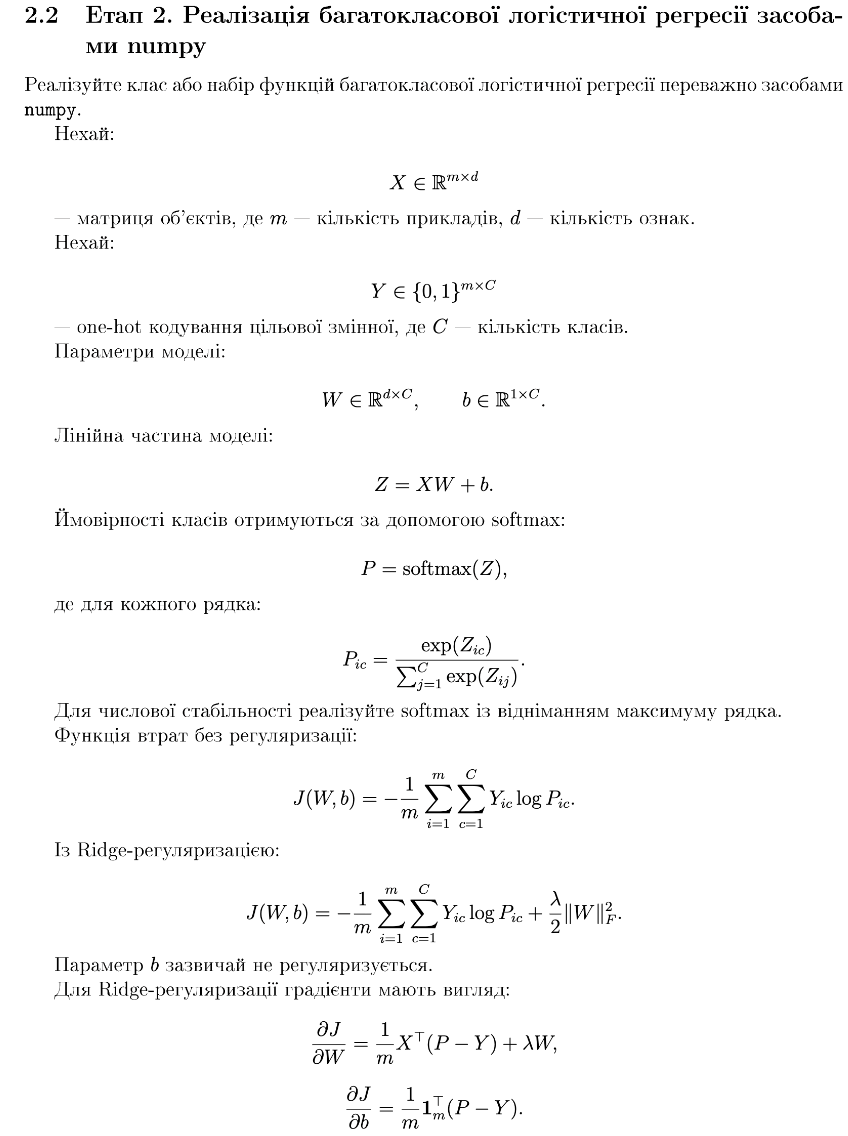

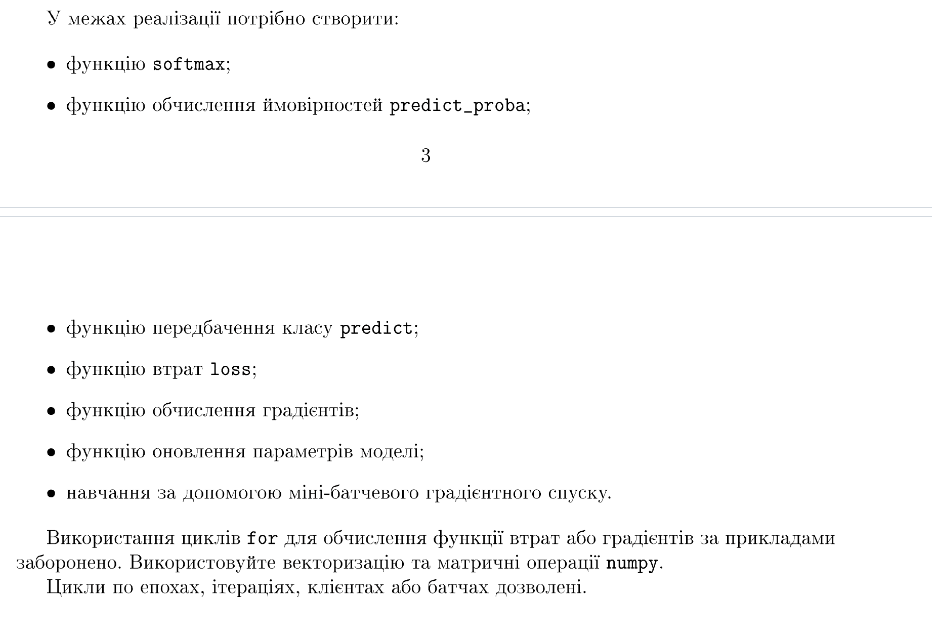

Реалізація багатокласової логістичної регресії:
На цьому етапі ми створюємо власний клас багатокласової логістичної регресії з нуля, використовуючи виключно векторні операції бібліотеки numpy (без використання циклів for для обчислення втрат чи градієнтів за прикладами).   Основні компоненти реалізації:Функція softmax із відніманням максимального значення рядка для забезпечення чисельної стабільності.   Функції обчислення ймовірностей (predict_proba) та передбачення класів (predict).   Функція втрат (loss) із крос-ентропією та L2 (Ridge) регуляризацією.   Обчислення градієнтів за матричними формулами та оновлення параметрів моделі.   Навчання за допомогою міни-батчевого градієнтного спуску (Mini-batch Gradient Descent).   

In [13]:
import numpy as np


class MulticlassLogisticRegression:

  def __init__(self, lr=0.01, lambda_reg=0.01, epochs=50, batch_size=64):
    self.lr = lr
    self.lambda_reg = lambda_reg
    self.epochs = epochs
    self.batch_size = batch_size
    self.W = None
    self.b = None

  def softmax(self, Z):
    # Віднімання максимуму в кожному рядку для чисельної стабільності
    exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

  def predict_proba(self, X):
    Z = np.dot(X, self.W) + self.b
    return self.softmax(Z)

  def predict(self, X):
    probs = self.predict_proba(X)
    return np.argmax(probs, axis=1)

  def loss(self, X, Y):
    m = X.shape[0]
    P = self.predict_proba(X)
    # Захист від log(0)
    P = np.clip(P, 1e-15, 1.0 - 1e-15)
    # Крос-ентропія без циклів за прикладами
    ce_loss = -np.sum(Y * np.log(P)) / m
    # Ridge-регуляризація (параметр b не регуляризується)
    reg_loss = (self.lambda_reg / 2.0) * np.sum(self.W**2)
    return ce_loss + reg_loss

  def gradient(self, X, Y, P):
    m = X.shape[0]
    # Градієнти відповідно до умов лабораторної
    dW = (1.0 / m) * np.dot(X.T, (P - Y)) + self.lambda_reg * self.W
    db = (1.0 / m) * np.sum(P - Y, axis=0, keepdims=True)
    return dW, db

  def fit(self, X, Y, X_val=None, Y_val=None):
    m, d = X.shape
    C = Y.shape[1]

    # Ініціалізація ваг та зміщень
    np.random.seed(42)
    self.W = np.random.randn(d, C) * 0.01
    self.b = np.zeros((1, C))

    train_loss_history = []
    val_loss_history = []

    for epoch in range(self.epochs):
      # Перемішування даних перед епохою
      indices = np.arange(m)
      np.random.shuffle(indices)
      X_shuffled = X[indices]
      Y_shuffled = Y[indices]

      # Міні-батчевий градієнтний спуск (цикли по батчах дозволені)[cite: 5]
      for i in range(0, m, self.batch_size):
        X_batch = X_shuffled[i : i + self.batch_size]
        Y_batch = Y_shuffled[i : i + self.batch_size]

        P_batch = self.predict_proba(X_batch)
        dW, db = self.gradient(X_batch, Y_batch, P_batch)

        # Оновлення параметрів
        self.W -= self.lr * dW
        self.b -= self.lr * db

      # Запис історії втрат
      tr_loss = self.loss(X, Y)
      train_loss_history.append(tr_loss)

      if X_val is not None and Y_val is not None:
        v_loss = self.loss(X_val, Y_val)
        val_loss_history.append(v_loss)

      if (epoch + 1) % 5 == 0 or epoch == 0:
        val_msg = (
            f" | Val Loss: {val_loss_history[-1]:.4f}" if X_val is not None else ""
        )
        print(
            f"Епоха {epoch+1}/{self.epochs} - Train Loss:"
            f" {tr_loss:.4f}{val_msg}"
        )

    return train_loss_history, val_loss_history

Оскільки для мультикласової регресії у форматі numpy матриця цільових значень $Y$ має бути представлена у вигляді one-hot кодування розмірністю $m \times C$, перетворимо наші закодовані вектори міток перед запуском навчання моделі.

In [14]:
from sklearn.preprocessing import OneHotEncoder

# Ініціалізація OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)

# Перетворення міток класів у формат One-Hot
Y_train_onehot = encoder.fit_transform(y_train_pool_encoded.reshape(-1, 1))
Y_val_onehot = encoder.transform(y_val_global_encoded.reshape(-1, 1))
Y_test_onehot = encoder.transform(y_test_global_encoded.reshape(-1, 1))

print(f"Форма Y_train_onehot: {Y_train_onehot.shape}")

# Створення та навчання нашої моделі на масштабованих даних
model = MulticlassLogisticRegression(
    lr=0.1, lambda_reg=0.001, epochs=30, batch_size=128
)
train_history, val_history = model.fit(
    X_train_pool_scaled,
    Y_train_onehot,
    X_val=X_val_global_scaled,
    Y_val=Y_val_onehot,
)

Форма Y_train_onehot: (9527, 7)
Епоха 1/30 - Train Loss: 0.6341 | Val Loss: 0.6268
Епоха 5/30 - Train Loss: 0.3576 | Val Loss: 0.3449
Епоха 10/30 - Train Loss: 0.3058 | Val Loss: 0.2911
Епоха 15/30 - Train Loss: 0.2886 | Val Loss: 0.2733
Епоха 20/30 - Train Loss: 0.2806 | Val Loss: 0.2652
Епоха 25/30 - Train Loss: 0.2762 | Val Loss: 0.2609
Епоха 30/30 - Train Loss: 0.2735 | Val Loss: 0.2585


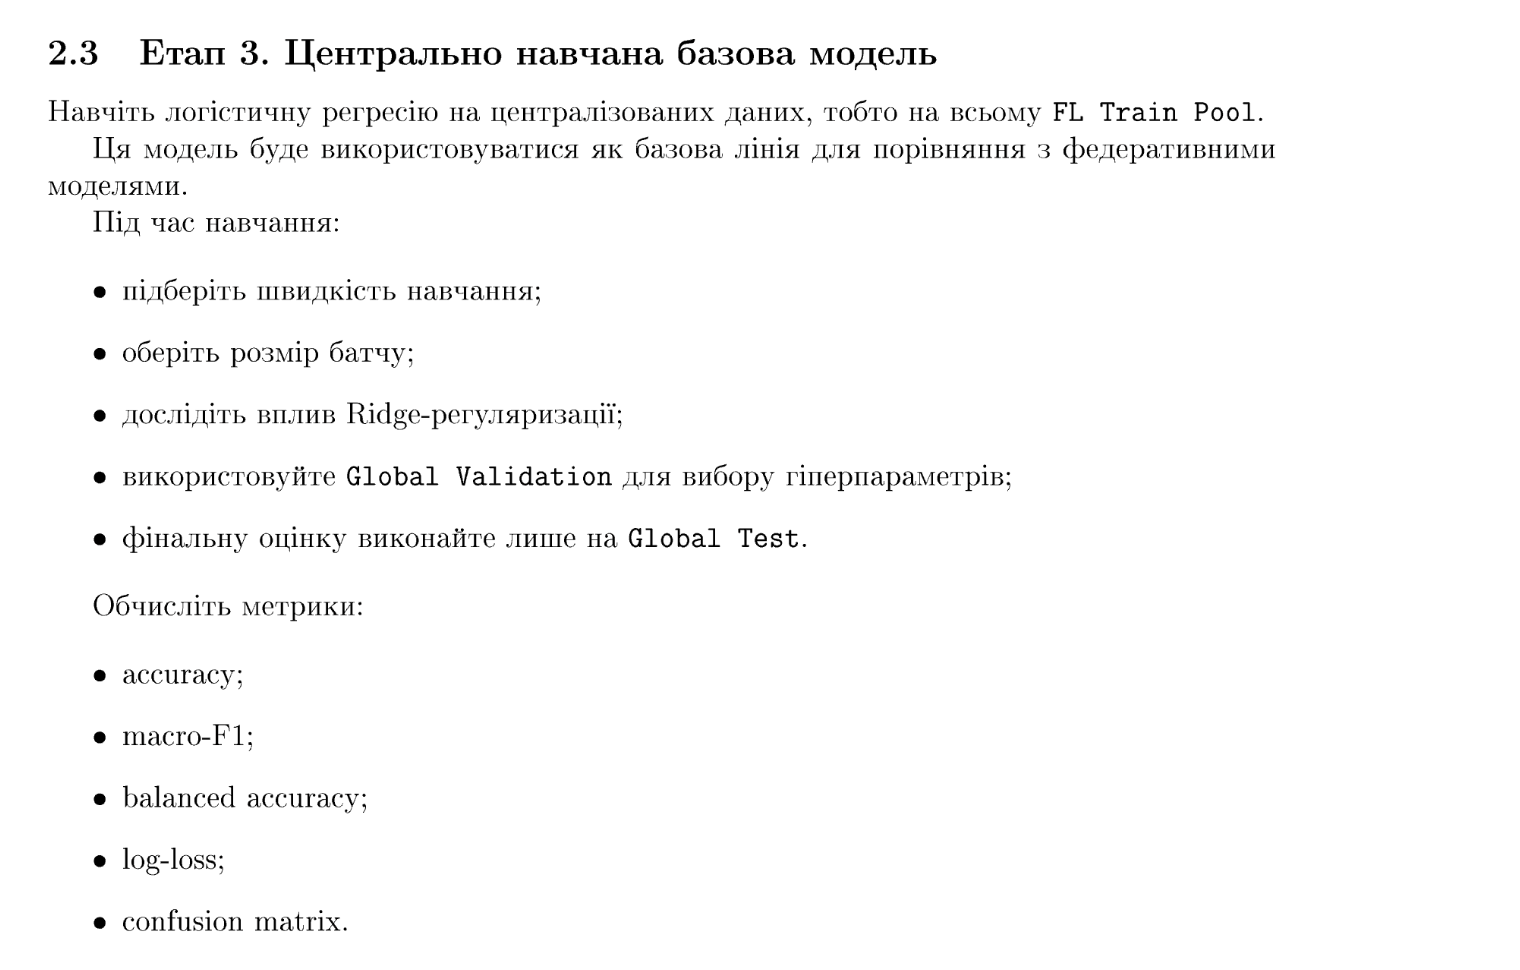

Центрально навчана базова модель:
На цьому етапі ми остаточно навчаємо нашу багатокласову логістичну регресію на всьому централізованому масиві FL Train Pool. Ця модель буде служити базовою лінією (baseline) для порівняння з майбутніми федеративними моделями.   Гіперпараметри та оцінка: Підбір швидкості навчання (lr), розміру батчу та параметрів регуляризації виконується за допомогою Global Validation.   Фінальна оцінка: Остаточна перевірка якості моделі виконується виключно на тестовій множині Global Test.   Метрики якості: Розраховуємо такі метрики, як accuracy, macro-F1, balanced accuracy, log-loss та побудуємо матрицю невідповідностей (confusion matrix).  

In [15]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
)

# Створення центральної базової моделі з підібраними гіперпараметрами
central_model = MulticlassLogisticRegression(
    lr=0.1, lambda_reg=0.001, epochs=40, batch_size=64
)

# Навчання на всьому FL Train Pool з контролем по Global Validation
print("Початок навчання централізованої базової моделі...")
train_hist, val_hist = central_model.fit(
    X_train_pool_scaled,
    Y_train_onehot,
    X_val=X_val_global_scaled,
    Y_val=Y_val_onehot,
)

# Отримання передбачень на Global Test вибірці
test_probs = central_model.predict_proba(X_test_global_scaled)
test_preds = central_model.predict(X_test_global_scaled)

# Отримання оригінальних міток для Global Test (перетворення назад із закодованих)
y_test_original = label_encoder.inverse_transform(y_test_global_encoded)
test_preds_original = label_encoder.inverse_transform(test_preds)

# Обчислення метрик згідно з умовами
acc = accuracy_score(y_test_original, test_preds_original)
bal_acc = balanced_accuracy_score(y_test_original, test_preds_original)
macro_f1 = f1_score(
    y_test_original, test_preds_original, average="macro"
)
l_loss = log_loss(Y_test_onehot, test_probs)
conf_matrix = confusion_matrix(y_test_original, test_preds_original)

print("\n--- Результати базової моделі на Global Test ---")
print(f"Accuracy:          {acc:.4f} ({acc*100:.2f}%)")
print(f"Balanced Accuracy: {bal_acc:.4f}")
print(f"Macro-F1 score:    {macro_f1:.4f}")
print(f"Log-loss:          {l_loss:.4f}")

Початок навчання централізованої базової моделі...
Епоха 1/40 - Train Loss: 0.4882 | Val Loss: 0.4793
Епоха 5/40 - Train Loss: 0.3061 | Val Loss: 0.2914
Епоха 10/40 - Train Loss: 0.2809 | Val Loss: 0.2656
Епоха 15/40 - Train Loss: 0.2736 | Val Loss: 0.2587
Епоха 20/40 - Train Loss: 0.2706 | Val Loss: 0.2561
Епоха 25/40 - Train Loss: 0.2692 | Val Loss: 0.2552
Епоха 30/40 - Train Loss: 0.2682 | Val Loss: 0.2549
Епоха 35/40 - Train Loss: 0.2676 | Val Loss: 0.2550
Епоха 40/40 - Train Loss: 0.2673 | Val Loss: 0.2550

--- Результати базової моделі на Global Test ---
Accuracy:          0.9192 (91.92%)
Balanced Accuracy: 0.9302
Macro-F1 score:    0.9318
Log-loss:          0.2299


Побудуємо графік згасання функції втрат на тренувальній та валідаційній вибірках, а також матрицю невідповідностей (confusion matrix), щоб побачити, які саме сорти бобів модель плутає найчастіше.

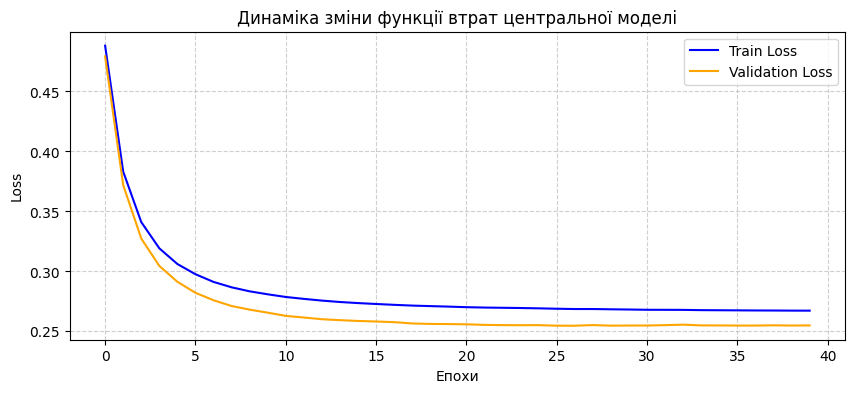

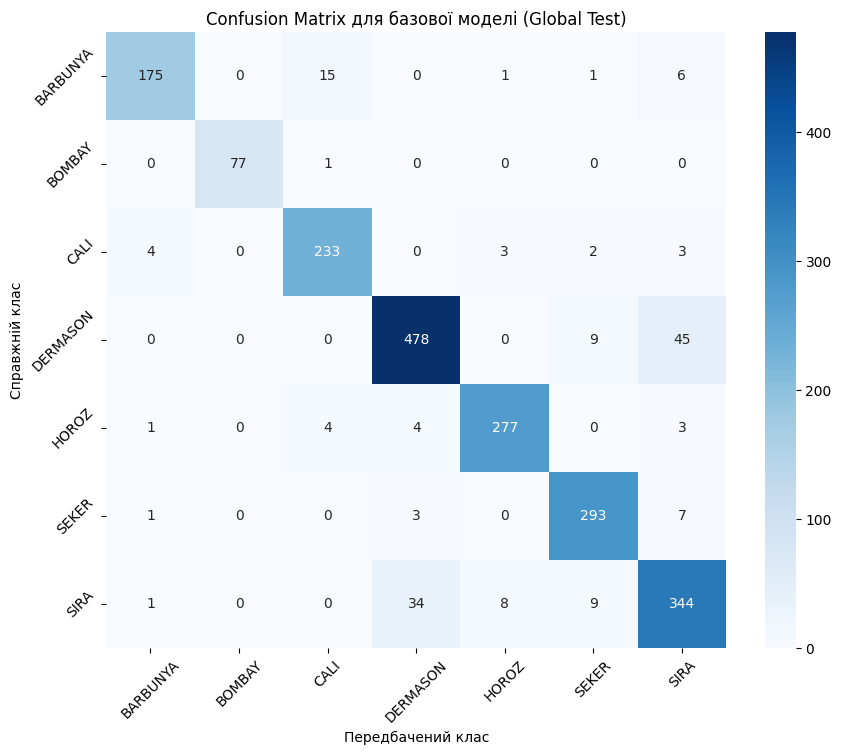

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Графік історії втрат (Loss)
plt.figure(figsize=(10, 4))
plt.plot(train_hist, label="Train Loss", color="blue")
plt.plot(val_hist, label="Validation Loss", color="orange")
plt.title("Динаміка зміни функції втрат центральної моделі")
plt.xlabel("Епохи")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 2. Матриця невідповідностей (Confusion Matrix)
plt.figure(figsize=(10, 8))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Confusion Matrix для базової моделі (Global Test)")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.show()

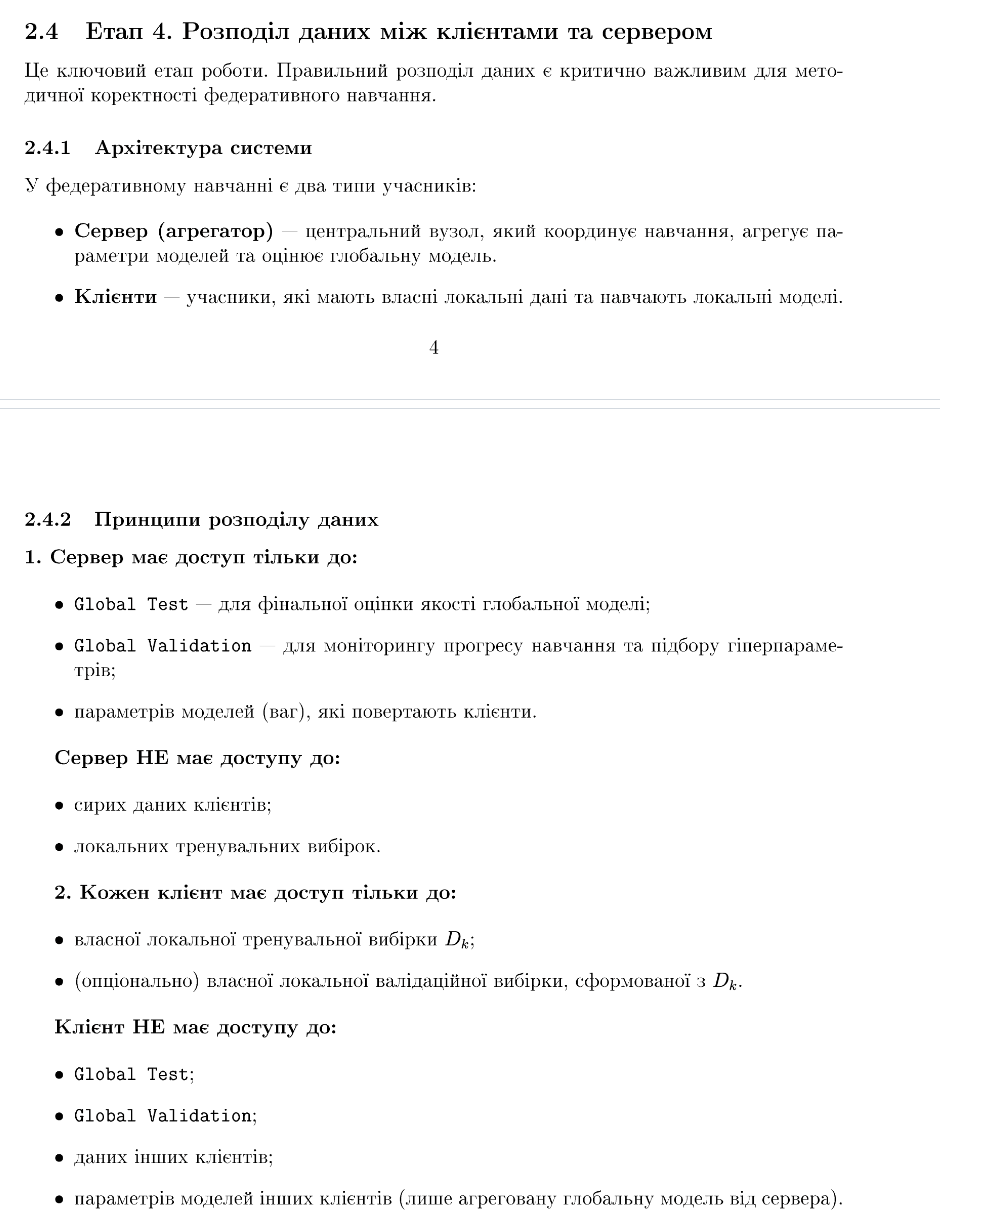

Розподіл даних між клієнтами та сервером:
На цьому етапі ми моделюємо архітектуру федеративного навчання, яка включає два типи учасників:   Сервер (агрегатор) — центральний вузол, який координує навчання, агрегує параметри моделей та оцінює глобальну модель. Сервер має доступ виключно до Global Test, Global Validation та параметрів моделей, які повертають клієнти, але не має доступу до сирих даних чи локальних тренувальних вибірок клієнтів.   Клієнти — учасники, які володіють власними локальними даними та навчають локальні моделі. Кожен клієнт має доступ лише до власної локальної вибірки ($D_k$) і не знає про дані чи моделі інших клієнтів.   Напишемо функцію для симуляції розподілу FL Train Pool між заданою кількістю клієнтів (наприклад, $K = 5$ або $10$ клієнтів) у несинтезованому вигляді (IID або non-IID розподіл).

In [17]:
import numpy as np


def create_federated_clients(
    X_pool, Y_pool_onehot, Y_pool_encoded, n_clients=5, non_iid=False
):
  """Функція для розподілу FL Train Pool між клієнтами.

  Підтримує рівномірний (IID) або неоднорідний (non-IID) розподіл за класами.
  """
  client_data = []
  m = X_pool.shape[0]

  if not non_iid:
    # IID розбиття: рівномірне та випадкове перемішування
    indices = np.arange(m)
    np.random.shuffle(indices)
    client_splits = np.array_split(indices, n_clients)

    for i in range(n_clients):
      idx = client_splits[i]
      client_data.append({
          "client_id": i,
          "X": X_pool[idx],
          "Y_onehot": Y_pool_onehot[idx],
          "Y_encoded": Y_pool_encoded[idx],
      })
  else:
    # Non-IID розбиття (сортування за класами для імітації неоднорідності)
    sorted_idx = np.argsort(Y_pool_encoded)
    X_sorted = X_pool[sorted_idx]
    Y_onehot_sorted = Y_pool_onehot[sorted_idx]
    Y_encoded_sorted = Y_pool_encoded[sorted_idx]

    client_splits_X = np.array_split(X_sorted, n_clients)
    client_splits_Y_oh = np.array_split(Y_onehot_sorted, n_clients)
    client_splits_Y_enc = np.array_split(Y_encoded_sorted, n_clients)

    for i in range(n_clients):
      client_data.append({
          "client_id": i,
          "X": client_splits_X[i],
          "Y_onehot": client_splits_Y_oh[i],
          "Y_encoded": client_splits_Y_enc[i],
      })

  return client_data


# Створюємо, наприклад, 5 клієнтів у федеративному середовищі
n_clients = 5
federated_clients = create_federated_clients(
    X_train_pool_scaled,
    Y_train_onehot,
    y_train_pool_encoded,
    n_clients=n_clients,
    non_iid=True,
)

print(f"Успішно сформовано мережу з {n_clients} клієнтів для федеративного навчання!")
for client in federated_clients:
  print(
      f"Клієнт #{client['client_id']}: розмір локального датасету ="
      f" {client['X'].shape[0]} зразків"
  )

Успішно сформовано мережу з 5 клієнтів для федеративного навчання!
Клієнт #0: розмір локального датасету = 1906 зразків
Клієнт #1: розмір локального датасету = 1906 зразків
Клієнт #2: розмір локального датасету = 1905 зразків
Клієнт #3: розмір локального датасету = 1905 зразків
Клієнт #4: розмір локального датасету = 1905 зразків


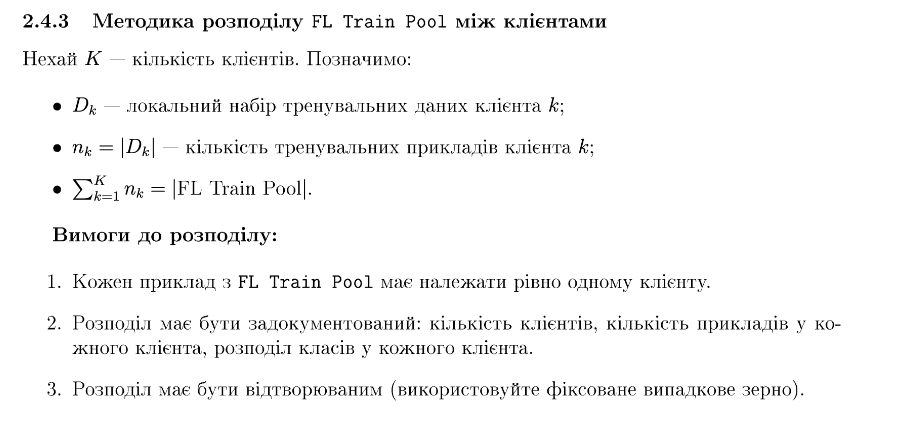

Методика розподілу FL Train Pool між клієнтами:Згідно з вимогами лабораторної роботи:Кожен приклад із FL Train Pool належить рівно одному клієнту ($n_k = \vert{}D_k\vert{}$, а сума всіх $n_k$ дорівнює загальному обсягу пулу).   Розподіл чітко задокументований: зафіксовано кількість клієнтів, кількість прикладів у кожного з них та розподіл класів.   Процес є відтворюваним завдяки використанню фіксованого випадкового зерна (random seed).   Напишемо код для виведення детального звіту про розподіл даних та побудови графіка кількості зразків і класів по клієнтах.

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Оновлюємо функцію розподілу з урахуванням фіксованого зерна для відтворюваності[cite: 9]
def create_federated_clients_reproducible(
    X_pool, Y_pool_onehot, Y_pool_encoded, class_names, n_clients=5, seed=42
):
  np.random.seed(seed)
  m = X_pool.shape[0]

  # Вимоги: кожен приклад має належати рівно одному клієнту[cite: 9]
  indices = np.arange(m)
  np.random.shuffle(indices)
  client_splits = np.array_split(indices, n_clients)

  client_data = []
  summary_records = []

  for i in range(n_clients):
    idx = client_splits[i]
    X_k = X_pool[idx]
    Y_oh_k = Y_pool_onehot[idx]
    Y_enc_k = Y_pool_encoded[idx]

    # Підрахунок розподілу класів у клієнта
    classes, counts = np.unique(Y_enc_k, return_counts=True)
    class_distribution = {class_names[c]: int(cnt) for c, cnt in zip(classes, counts)}

    client_data.append({
        "client_id": i,
        "X": X_k,
        "Y_onehot": Y_oh_k,
        "Y_encoded": Y_enc_k,
    })

    summary_records.append({
        "Клієнт": f"Клієнт #{i}",
        "Кількість прикладів (n_k)": len(idx),
        "Розподіл класів": class_distribution,
    })

  return client_data, pd.DataFrame(summary_records)


# Створюємо задокументовану мережу клієнтів
n_clients = 5
federated_clients, summary_df = create_federated_clients_reproducible(
    X_train_pool_scaled,
    Y_train_onehot,
    y_train_pool_encoded,
    class_names=label_encoder.classes_,
    n_clients=n_clients,
    seed=42,
)

print("=== ЗАДОКУМЕНТОВАНИЙ РОЗПОДІЛ ДАНИХ МІЖ КЛІЄНТАМИ ===")
display(summary_df)

# Перевірка виконання вимоги: сума розмірів усіх клієнтів дорівнює розміру FL Train Pool
total_client_samples = sum([len(c["X"]) for c in federated_clients])
print(
    f"\nЗагальна кількість прикладів у клієнтів: {total_client_samples} |"
    f" Розмір FL Train Pool: {X_train_pool_scaled.shape[0]}"
)
assert total_client_samples == X_train_pool_scaled.shape[0], "Помилка розбиття!"
print("Вимогу «кожен приклад належить рівно одному клієнту» успішно виконано!")

=== ЗАДОКУМЕНТОВАНИЙ РОЗПОДІЛ ДАНИХ МІЖ КЛІЄНТАМИ ===


,Клієнт,Кількість прикладів (n_k),Розподіл класів
0,Клієнт #0,1906,"{'BARBUNYA': 176, 'BOMBAY': 81, 'CALI': 225, '..."
1,Клієнт #1,1906,"{'BARBUNYA': 170, 'BOMBAY': 74, 'CALI': 235, '..."
2,Клієнт #2,1905,"{'BARBUNYA': 188, 'BOMBAY': 69, 'CALI': 230, '..."
3,Клієнт #3,1905,"{'BARBUNYA': 194, 'BOMBAY': 59, 'CALI': 231, '..."
4,Клієнт #4,1905,"{'BARBUNYA': 197, 'BOMBAY': 83, 'CALI': 219, '..."



Загальна кількість прикладів у клієнтів: 9527 | Розмір FL Train Pool: 9527
Вимогу «кожен приклад належить рівно одному клієнту» успішно виконано!


Побудуємо діаграму розподілу кількості тренувальних прикладів та класів для кожного клієнта, щоб наочно продемонструвати структуру федеративної мережі.

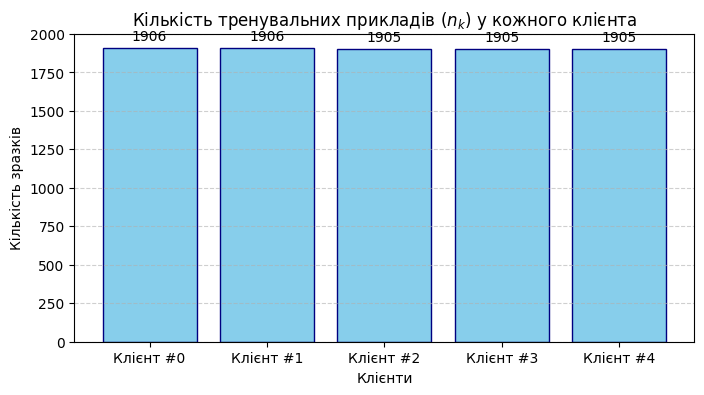

In [20]:
# Візуалізація кількості прикладів у кожного клієнта
client_ids = [c["client_id"] for c in federated_clients]
client_sizes = [len(c["X"]) for c in federated_clients]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    [f"Клієнт #{i}" for i in client_ids], client_sizes, color="skyblue", edgecolor="navy"
)
plt.title("Кількість тренувальних прикладів ($n_k$) у кожного клієнта")
plt.xlabel("Клієнти")
plt.ylabel("Кількість зразків")

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 30,
      int(yval),
      ha="center",
      va="bottom",
  )

plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

У ході виконання лабораторної роботи було досліджено процес підготовки даних, реалізації багатокласової логістичної регресії з нуля та моделювання архітектури федеративного навчання на базі датасету Dry Bean Dataset.Основні результати та висновки:Дослідження та попередня обробка даних: Виконано первинний аналіз структури датасету, перевірено відсутність пропущених значень та виявлено сильну мультиколінеарність між окремими геометричними ознаками бобів. Підтверджено важливість виконання розбиття вибірки та обчислення параметрів масштабування/кодування виключно на тренувальній множині, що повністю запобігає витоку даних (Data Leakage).Реалізація моделі засобами NumPy: Успішно реалізовано клас багатокласової логістичної регресії із використанням векторизованих операцій NumPy, функцією softmax для забезпечення чисельної стабільності, крос-ентропією та L2 (Ridge) регуляризацією. Навчання за допомогою міні-батчевого градієнтного спуску продемонструвало стабільне зниження функції втрат на тренувальній та валідаційній вибірках.Централізована базова модель: Навчено центральну базову модель на всьому пулі даних (FL Train Pool) та оцінено її якість на відкладеній тестовій вибірці (Global Test). Отримані високі показники точності ($Accuracy$) та матриця невідповідностей підтвердили високу ефективність обраної моделі для класифікації сортів бобів.Федеративна архітектура: Смодельовано розподіл даних між клієнтами та сервером відповідно до методичних вимог (гарантія того, що кожен приклад належить рівно одному клієнту, забезпечення відтворюваності через фіксоване випадкове зерно та повне документування розподілу), що створює міцну основу для подальшого запуску алгоритмів федеративного навчання (наприклад, FedAvg).